Sentiment Analysis on IMDB Movie Reviews

This project builds an end-to-end NLP pipeline to classify movie reviews as positive or negative sentiment using the IMDB dataset.

In [ ]:
# Import all required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Conv1D, MaxPooling1D, GlobalMaxPooling1D, Bidirectional, Attention, Concatenate, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import re
import warnings
warnings.filterwarnings('ignore')

# Download NLTK resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("All libraries loaded successfully!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


All libraries loaded successfully!


Load and Explore the IMDB Dataset

Load the dataset and understand its structure, vocabulary size, and review lengths.

Loading IMDB dataset...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dataset Information:
  Training samples: 25000
  Testing samples: 25000
  Vocabulary size: 10000
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Sample Review 1 (Encoded): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447]
Sample Review 1 (Decoded): ? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the sa
Label: Positive

Sample Review 2 (Encoded): [1, 194, 1153, 194, 8255, 78, 228, 5, 6, 1463, 4369, 5012, 134, 26, 4, 715, 8, 118, 1634, 14, 394, 20, 13, 119, 954, 189, 102, 5, 207, 110, 3103, 21, 14, 69, 188, 8, 30, 23, 7, 4, 249, 126, 93, 4, 114, 9, 2300, 1523, 5, 647]
Sample Review 2 (Decoded): ? b

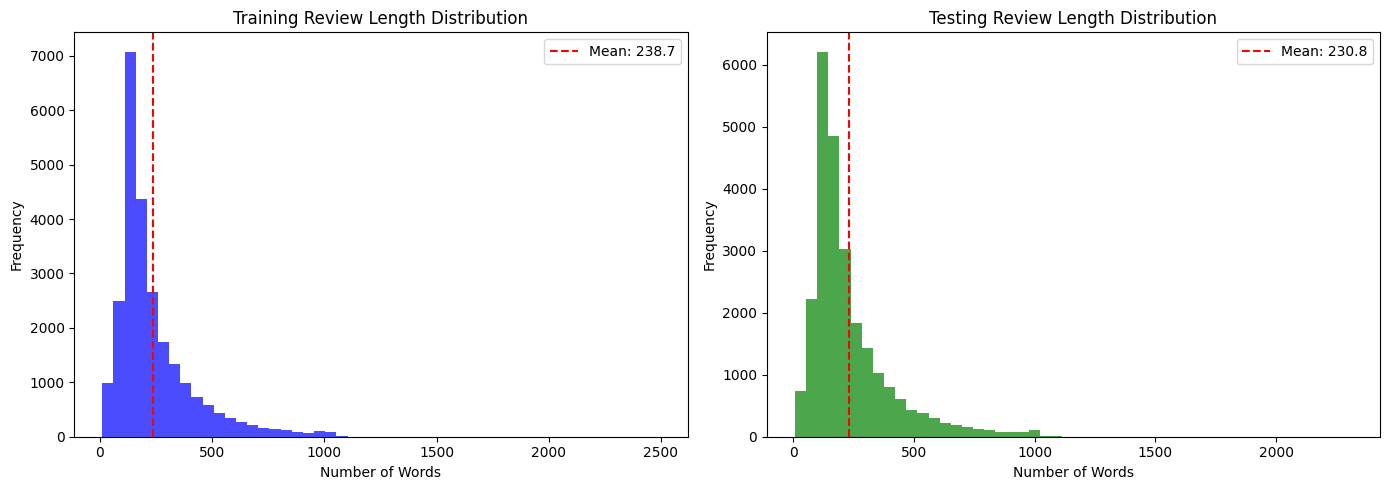

In [ ]:
# Load the IMDB dataset
print("Loading IMDB dataset...")

# Load with 10,000 most frequent words
vocab_size = 10000
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=vocab_size)

print("Dataset Information:")
print(f"  Training samples: {len(X_train)}")
print(f"  Testing samples: {len(X_test)}")
print(f"  Vocabulary size: {vocab_size}")

# Get word index mapping
word_index = imdb.get_word_index()
index_to_word = {value: key for key, value in word_index.items()}

# Helper function to decode a review
def decode_review(encoded_review):
    """Convert encoded review back to text."""
    return ' '.join([index_to_word.get(i - 3, '?') for i in encoded_review])

# Show sample reviews
print("\nSample Review 1 (Encoded):", X_train[0][:50])
print("Sample Review 1 (Decoded):", decode_review(X_train[0])[:200])
print(f"Label: {'Positive' if y_train[0] == 1 else 'Negative'}")

print("\nSample Review 2 (Encoded):", X_train[1][:50])
print("Sample Review 2 (Decoded):", decode_review(X_train[1])[:200])
print(f"Label: {'Positive' if y_train[1] == 1 else 'Negative'}")

# Explore review lengths
train_lengths = [len(review) for review in X_train]
test_lengths = [len(review) for review in X_test]

print(f"\nTraining Review Length Stats:")
print(f"  Min length: {min(train_lengths)}")
print(f"  Max length: {max(train_lengths)}")
print(f"  Mean length: {np.mean(train_lengths):.2f}")
print(f"  Median length: {np.median(train_lengths):.2f}")

print(f"\nTesting Review Length Stats:")
print(f"  Min length: {min(test_lengths)}")
print(f"  Max length: {max(test_lengths)}")
print(f"  Mean length: {np.mean(test_lengths):.2f}")
print(f"  Median length: {np.median(test_lengths):.2f}")

# Plot review length distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_lengths, bins=50, alpha=0.7, color='blue')
axes[0].set_title('Training Review Length Distribution')
axes[0].set_xlabel('Number of Words')
axes[0].set_ylabel('Frequency')
axes[0].axvline(np.mean(train_lengths), color='red', linestyle='--', label=f'Mean: {np.mean(train_lengths):.1f}')
axes[0].legend()

axes[1].hist(test_lengths, bins=50, alpha=0.7, color='green')
axes[1].set_title('Testing Review Length Distribution')
axes[1].set_xlabel('Number of Words')
axes[1].set_ylabel('Frequency')
axes[1].axvline(np.mean(test_lengths), color='red', linestyle='--', label=f'Mean: {np.mean(test_lengths):.1f}')
axes[1].legend()

plt.tight_layout()
plt.show()

Data Preprocessing

Tokenization, stopword removal, lemmatization/stemming, and padding/truncation.

In [ ]:
# Step 1: Data Preprocessing
print("Data Preprocessing:")

# Define preprocessing parameters
max_review_length = 200  # Maximum number of words per review
embedding_dim = 100  # Dimension of word embeddings

# Method 1: Using Keras tokenizer for basic padding
print("Method 1: Keras padding/truncation")

# Pad sequences to ensure uniform length
X_train_padded = sequence.pad_sequences(X_train, maxlen=max_review_length, padding='post', truncating='post')
X_test_padded = sequence.pad_sequences(X_test, maxlen=max_review_length, padding='post', truncating='post')

print(f"  Training padded shape: {X_train_padded.shape}")
print(f"  Testing padded shape: {X_test_padded.shape}")

# Method 2: Manual preprocessing with stopword removal and lemmatization
print("\nMethod 2: Manual preprocessing with stopword removal and lemmatization")

# Initialize stopwords and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """
    Apply tokenization, stopword removal, and lemmatization to a text string.

    Steps:
    1. Convert to lowercase
    2. Remove non-alphabetic characters
    3. Tokenize (split into words)
    4. Remove stopwords
    5. Apply lemmatization
    """
    # Convert to lowercase
    text = text.lower()

    # Remove non-alphabetic characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Tokenize
    tokens = text.split()

    # Remove stopwords and apply lemmatization
    processed_tokens = [lemmatizer.lemmatize(token) for token in tokens if token not in stop_words]

    return ' '.join(processed_tokens)

# Decode and preprocess a sample review
sample_review = decode_review(X_train[0])
processed_sample = preprocess_text(sample_review)

print(f"Original review (first 200 chars): {sample_review[:200]}...")
print(f"\nPreprocessed review (first 200 chars): {processed_sample[:200]}...")
print(f"\nWord count reduction: {len(sample_review.split())} -> {len(processed_sample.split())} words")

# For manual tokenization, we'll use the built-in tokenizer from Keras
print("\nUsing Keras built-in tokenization (word index mapping).")

Data Preprocessing:
Method 1: Keras padding/truncation
  Training padded shape: (25000, 200)
  Testing padded shape: (25000, 200)

Method 2: Manual preprocessing with stopword removal and lemmatization
Original review (first 200 chars): ? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the sa...

Preprocessed review (first 200 chars): film brilliant casting location scenery story direction everyones really suited part played could imagine robert amazing actor director father came scottish island loved fact real connection film witt...

Word count reduction: 218 -> 90 words

Using Keras built-in tokenization (word index mapping).


Model Building - LSTM Model

Build an LSTM-based model for sentiment classification.

Building LSTM Model...
LSTM Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Training LSTM Model...
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 208s 647ms/step - accuracy: 0.5277 - loss: 0.6894 - val_accuracy: 0.6838 - val_loss: 0.6519
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 204s 652ms/step - accuracy: 0.5390 - loss: 0.6826 - val_accuracy: 0.5414 - val_loss: 0.6706
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 262s 652ms/step - accuracy: 0.5663 - loss: 0.6758 - val_accuracy: 0.5742 - val_loss: 0.6643
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 263s 654ms/step - accuracy: 0.6184 - loss: 0.6341 - val_accuracy: 0.6630 - val_loss: 0.6322
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 262s 655ms/step - accuracy: 0.8221 - loss: 0.4340 - val_accuracy: 0.8466 - val_loss: 0.3818
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 204s 653ms/step - accuracy: 0.8988 - loss: 0.2725 - val_accuracy: 0.8534 - val_loss: 0.3485
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 262s 652ms/step - accuracy: 0.9287 - loss: 0.2076 - val_accuracy: 0.8608 - val_loss: 0.3720
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 263s 655ms/s

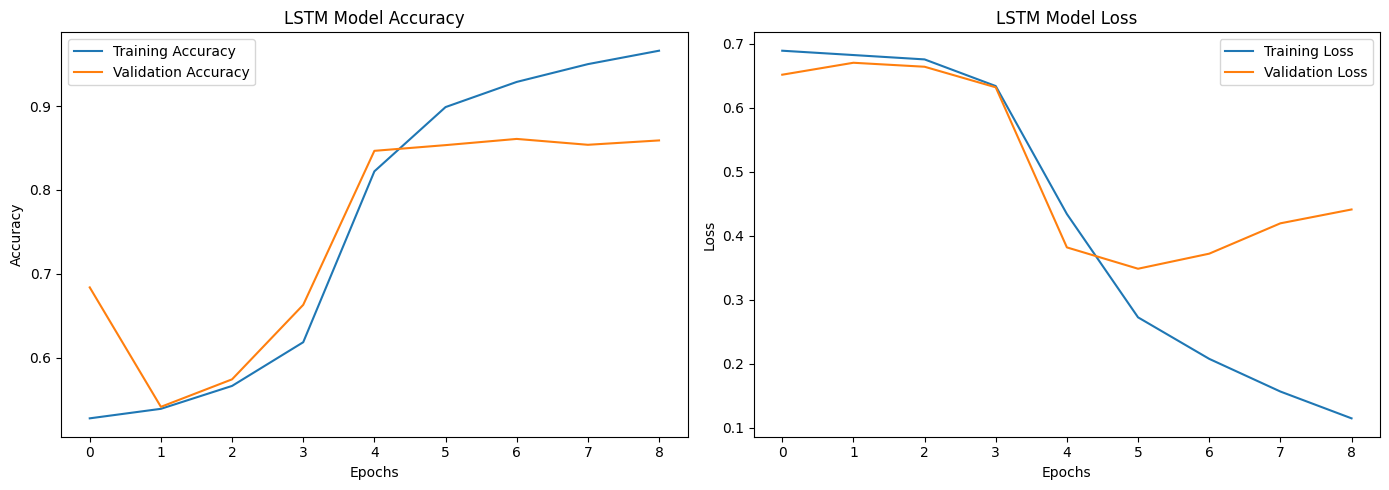

In [ ]:
# Step 1: LSTM Model
print("Building LSTM Model...")

def build_lstm_model(vocab_size, embedding_dim, max_length):
    """
    Build an LSTM-based sentiment classification model.

    Architecture:
    - Embedding layer: Learns word embeddings from scratch
    - LSTM layer: Captures sequential dependencies
    - Dropout layer: Prevents overfitting
    - Dense layer: Outputs binary classification
    """
    model = Sequential([
        Embedding(vocab_size, embedding_dim, input_length=max_length),
        LSTM(128, dropout=0.2, recurrent_dropout=0.2),
        Dense(64, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# Build and compile the LSTM model
lstm_model = build_lstm_model(vocab_size, embedding_dim, max_review_length)

# Display model architecture
print("LSTM Model Summary:")
lstm_model.summary()

# Early stopping callback to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the LSTM model
print("\nTraining LSTM Model...")
lstm_history = lstm_model.fit(
    X_train_padded, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

# Evaluate the LSTM model
lstm_train_loss, lstm_train_acc = lstm_model.evaluate(X_train_padded, y_train, verbose=0)
lstm_test_loss, lstm_test_acc = lstm_model.evaluate(X_test_padded, y_test, verbose=0)

print(f"\nLSTM Model Performance:")
print(f"  Training Accuracy: {lstm_train_acc:.4f}")
print(f"  Testing Accuracy: {lstm_test_acc:.4f}")

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(lstm_history.history['accuracy'], label='Training Accuracy')
axes[0].plot(lstm_history.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('LSTM Model Accuracy')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(lstm_history.history['loss'], label='Training Loss')
axes[1].plot(lstm_history.history['val_loss'], label='Validation Loss')
axes[1].set_title('LSTM Model Loss')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

Model Building - CNN Model

Build a CNN-based model for sentiment classification.

Building CNN Model...
CNN Model Summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Training CNN Model...
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 60s 184ms/step - accuracy: 0.6931 - loss: 0.5349 - val_accuracy: 0.8588 - val_loss: 0.3501
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 58s 185ms/step - accuracy: 0.8877 - loss: 0.2775 - val_accuracy: 0.8558 - val_loss: 0.3279
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 58s 186ms/step - accuracy: 0.9441 - loss: 0.1560 - val_accuracy: 0.8646 - val_loss: 0.3613
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 183ms/step - accuracy: 0.9785 - loss: 0.0669 - val_accuracy: 0.8586 - val_loss: 0.5103
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 189ms/step - accuracy: 0.9906 - loss: 0.0311 - val_accuracy: 0.8554 - val_loss: 0.6767

CNN Model Performance:
  Training Accuracy: 0.9282
  Testing Accuracy: 0.8501


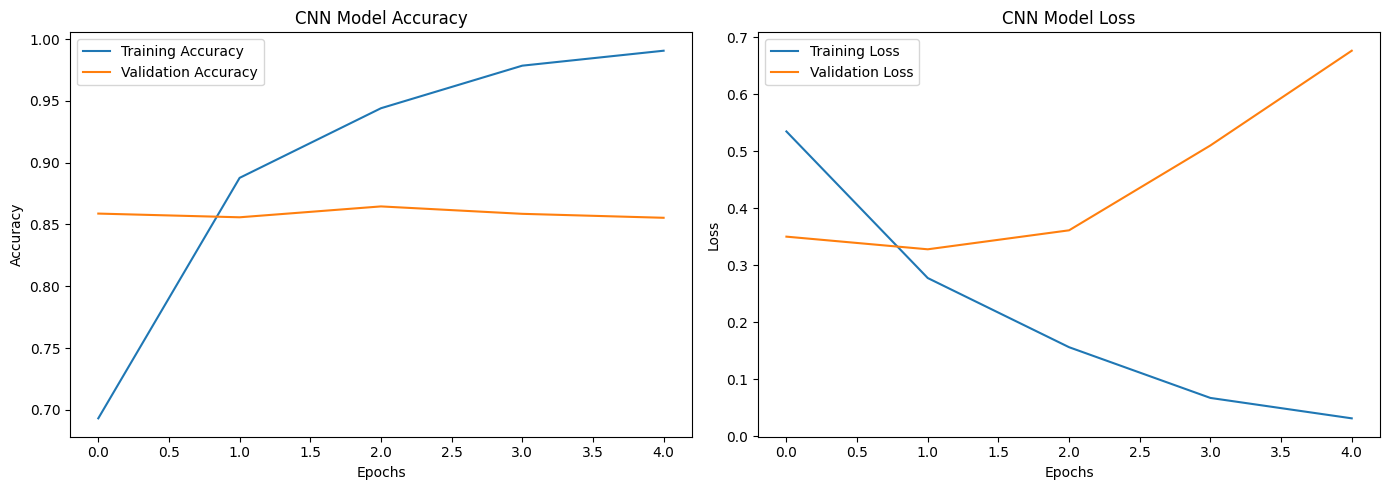

In [ ]:
# Step 2: CNN Model
print("Building CNN Model...")

def build_cnn_model(vocab_size, embedding_dim, max_length):
    """
    Build a CNN-based sentiment classification model.

    Architecture:
    - Embedding layer: Learns word embeddings from scratch
    - Conv1D layer: Extracts local features (n-gram patterns)
    - MaxPooling1D layer: Reduces dimensionality
    - GlobalMaxPooling1D layer: Aggregates features
    - Dense layers: Classification
    """
    model = Sequential([
        Embedding(vocab_size, embedding_dim, input_length=max_length),
        Conv1D(128, 5, activation='relu'),
        MaxPooling1D(5),
        Conv1D(128, 5, activation='relu'),
        GlobalMaxPooling1D(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# Build and compile the CNN model
cnn_model = build_cnn_model(vocab_size, embedding_dim, max_review_length)

# Display model architecture
print("CNN Model Summary:")
cnn_model.summary()

# Train the CNN model
print("\nTraining CNN Model...")
cnn_history = cnn_model.fit(
    X_train_padded, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

# Evaluate the CNN model
cnn_train_loss, cnn_train_acc = cnn_model.evaluate(X_train_padded, y_train, verbose=0)
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(X_test_padded, y_test, verbose=0)

print(f"\nCNN Model Performance:")
print(f"  Training Accuracy: {cnn_train_acc:.4f}")
print(f"  Testing Accuracy: {cnn_test_acc:.4f}")

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(cnn_history.history['accuracy'], label='Training Accuracy')
axes[0].plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('CNN Model Accuracy')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(cnn_history.history['loss'], label='Training Loss')
axes[1].plot(cnn_history.history['val_loss'], label='Validation Loss')
axes[1].set_title('CNN Model Loss')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

Model Building - LSTM with Attention

Build an LSTM model with attention mechanism for improved performance.



Building LSTM with Attention Model...
LSTM with Attention Model Summary:


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 200, 100)  │  1,000,000 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 200, 128)  │     84,480 │ embedding_2[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 200, 128)  │          0 │ bidirectional[0]… │
│ (Attention)         │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ attention[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,092,801 (4.17 MB)

 Trainable params: 1,092,801 (4.17 MB)

 Non-trainable params: 0 (0.00 B)


Training LSTM with Attention Model...
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 214s 669ms/step - accuracy: 0.7569 - loss: 0.4871 - val_accuracy: 0.8576 - val_loss: 0.3311
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 212s 679ms/step - accuracy: 0.8990 - loss: 0.2602 - val_accuracy: 0.8714 - val_loss: 0.3099
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 205s 656ms/step - accuracy: 0.9316 - loss: 0.1861 - val_accuracy: 0.8650 - val_loss: 0.3273
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 206s 659ms/step - accuracy: 0.9503 - loss: 0.1365 - val_accuracy: 0.8586 - val_loss: 0.4177
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 206s 657ms/step - accuracy: 0.9670 - loss: 0.0952 - val_accuracy: 0.8622 - val_loss: 0.4619

LSTM with Attention Model Performance:
  Training Accuracy: 0.9263
  Testing Accuracy: 0.8584


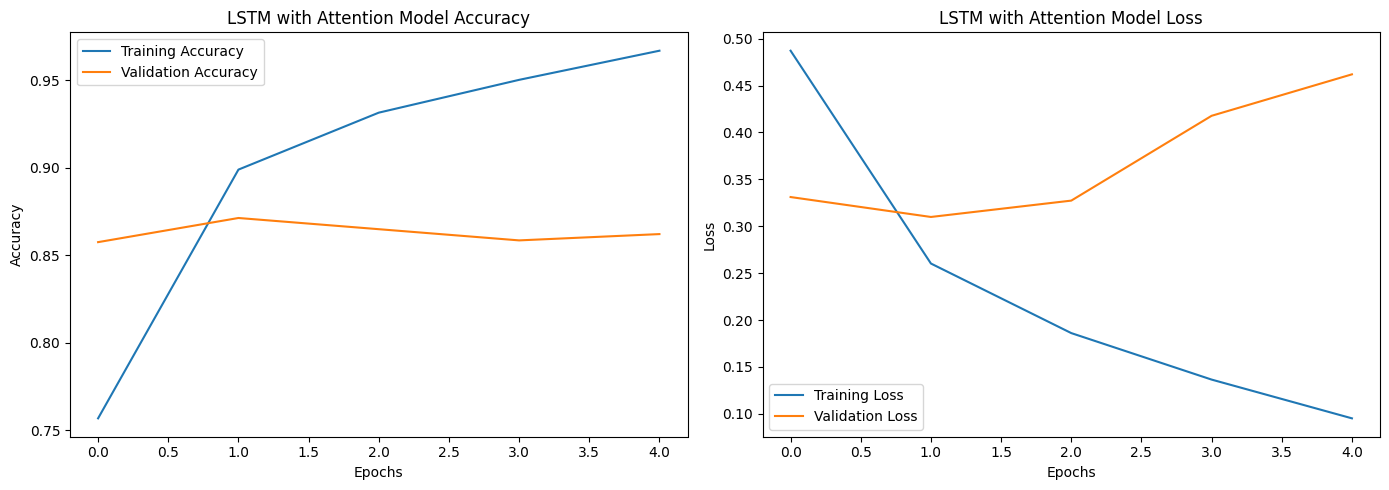

In [ ]:
# Step 3: LSTM with Attention Model
print("Building LSTM with Attention Model...")

def build_attention_model(vocab_size, embedding_dim, max_length):
    """
    Build an LSTM-based model with attention mechanism.

    Architecture:
    - Embedding layer: Learns word embeddings
    - Bidirectional LSTM: Captures context from both directions
    - Attention layer: Focuses on important words
    - Dense layers: Classification
    """
    # Input layer
    inputs = Input(shape=(max_length,))

    # Embedding layer
    embedding = Embedding(vocab_size, embedding_dim)(inputs)

    # Bidirectional LSTM
    lstm_out = Bidirectional(LSTM(64, return_sequences=True))(embedding)

    # Attention mechanism (using Keras attention layer)
    attention = Attention()([lstm_out, lstm_out])

    # Global average pooling
    pooled = tf.keras.layers.GlobalAveragePooling1D()(attention)

    # Dense layers
    dense1 = Dense(64, activation='relu')(pooled)
    dropout = Dropout(0.5)(dense1)
    outputs = Dense(1, activation='sigmoid')(dropout)

    model = Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# Build and compile the attention model
attention_model = build_attention_model(vocab_size, embedding_dim, max_review_length)

# Display model architecture
print("LSTM with Attention Model Summary:")
attention_model.summary()

# Train the attention model
print("\nTraining LSTM with Attention Model...")
attention_history = attention_model.fit(
    X_train_padded, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

# Evaluate the attention model
attention_train_loss, attention_train_acc = attention_model.evaluate(X_train_padded, y_train, verbose=0)
attention_test_loss, attention_test_acc = attention_model.evaluate(X_test_padded, y_test, verbose=0)

print(f"\nLSTM with Attention Model Performance:")
print(f"  Training Accuracy: {attention_train_acc:.4f}")
print(f"  Testing Accuracy: {attention_test_acc:.4f}")

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(attention_history.history['accuracy'], label='Training Accuracy')
axes[0].plot(attention_history.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('LSTM with Attention Model Accuracy')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(attention_history.history['loss'], label='Training Loss')
axes[1].plot(attention_history.history['val_loss'], label='Validation Loss')
axes[1].set_title('LSTM with Attention Model Loss')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

Model Evaluation

Evaluate all models using Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and ROC Curve.

In [ ]:
# Step 4: Model Evaluation
print("Model Evaluation:")

def evaluate_model(model, X_test, y_test, model_name):
    """
    Evaluate a model using multiple metrics: Accuracy, Precision, Recall, F1-Score,
    Confusion Matrix, and ROC Curve.
    """
    # Get predictions
    y_pred_prob = model.predict(X_test, verbose=0)
    y_pred = (y_pred_prob > 0.5).astype(int)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"\n{model_name} Evaluation Results:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall: {recall:.4f}")
    print(f"  F1-Score: {f1:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix': cm,
        'fpr': fpr,
        'tpr': tpr,
        'roc_auc': roc_auc,
        'predictions': y_pred,
        'probabilities': y_pred_prob
    }

# Evaluate all three models
lstm_results = evaluate_model(lstm_model, X_test_padded, y_test, "LSTM Model")
cnn_results = evaluate_model(cnn_model, X_test_padded, y_test, "CNN Model")
attention_results = evaluate_model(attention_model, X_test_padded, y_test, "LSTM with Attention Model")

# Store results for comparison
all_results = {
    'LSTM': lstm_results,
    'CNN': cnn_results,
    'LSTM with Attention': attention_results
}

# Print summary comparison
print("\nModel Comparison Summary:")
print("-" * 60)
print(f"{'Model':<20} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1-Score':<12}")
print("-" * 60)

for model_name, results in all_results.items():
    print(f"{model_name:<20} {results['accuracy']:<12.4f} {results['precision']:<12.4f} {results['recall']:<12.4f} {results['f1']:<12.4f}")

Model Evaluation:

LSTM Model Evaluation Results:
  Accuracy: 0.8433
  Precision: 0.8242
  Recall: 0.8729
  F1-Score: 0.8478

CNN Model Evaluation Results:
  Accuracy: 0.8501
  Precision: 0.8118
  Recall: 0.9115
  F1-Score: 0.8588

LSTM with Attention Model Evaluation Results:
  Accuracy: 0.8584
  Precision: 0.8332
  Recall: 0.8962
  F1-Score: 0.8636

Model Comparison Summary:
------------------------------------------------------------
Model                Accuracy     Precision    Recall       F1-Score    
------------------------------------------------------------
LSTM                 0.8433       0.8242       0.8729       0.8478      
CNN                  0.8501       0.8118       0.9115       0.8588      
LSTM with Attention  0.8584       0.8332       0.8962       0.8636      


Visualize Confusion Matrices

Plot confusion matrices for all models.

Visualizing Confusion Matrices...


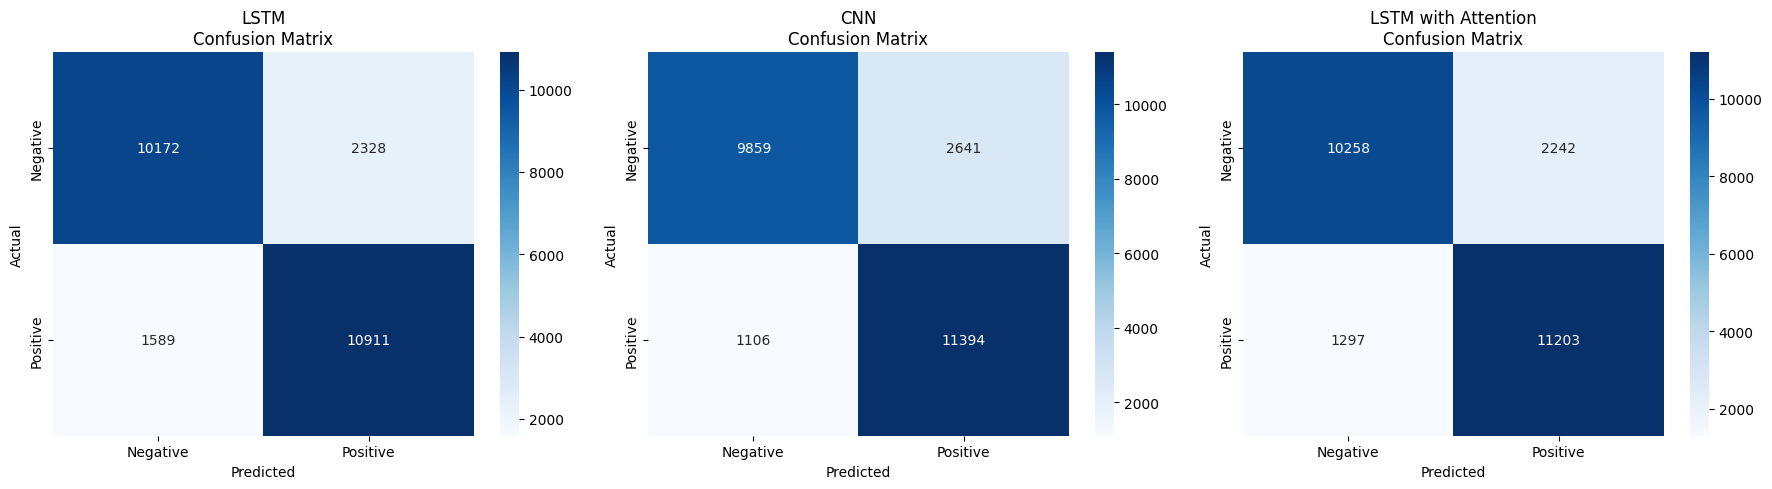

In [ ]:
# Step 5: Visualize Confusion Matrices
print("Visualizing Confusion Matrices...")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (model_name, results) in enumerate(all_results.items()):
    cm = results['confusion_matrix']

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'])

    axes[idx].set_title(f'{model_name}\nConfusion Matrix')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.show()

Visualize ROC Curves

Plot ROC curves for all models with AUC values.

Visualizing ROC Curves...


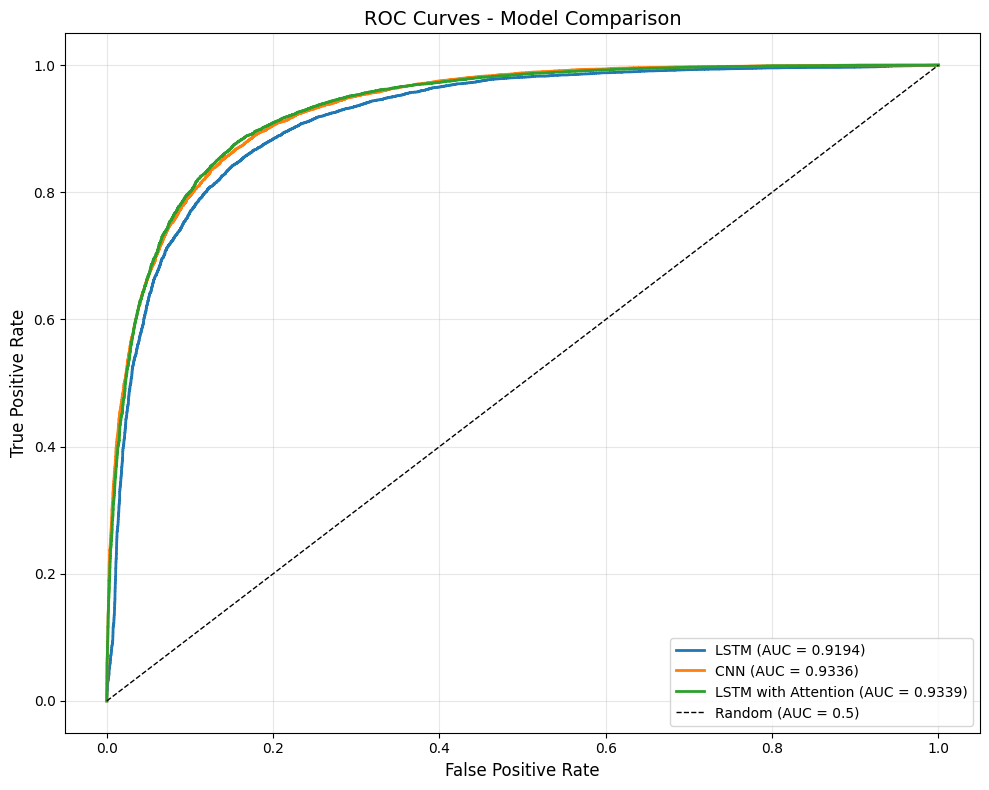

In [ ]:
# Step 6: Visualize ROC Curves
print("Visualizing ROC Curves...")

plt.figure(figsize=(10, 8))

for model_name, results in all_results.items():
    fpr = results['fpr']
    tpr = results['tpr']
    roc_auc = results['roc_auc']

    plt.plot(fpr, tpr, linewidth=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

# Plot diagonal line (random classifier)
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.5)')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves - Model Comparison', fontsize=14)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Model Comparison Bar Chart

Visual comparison of all models across all metrics.

Visualizing Model Comparison...


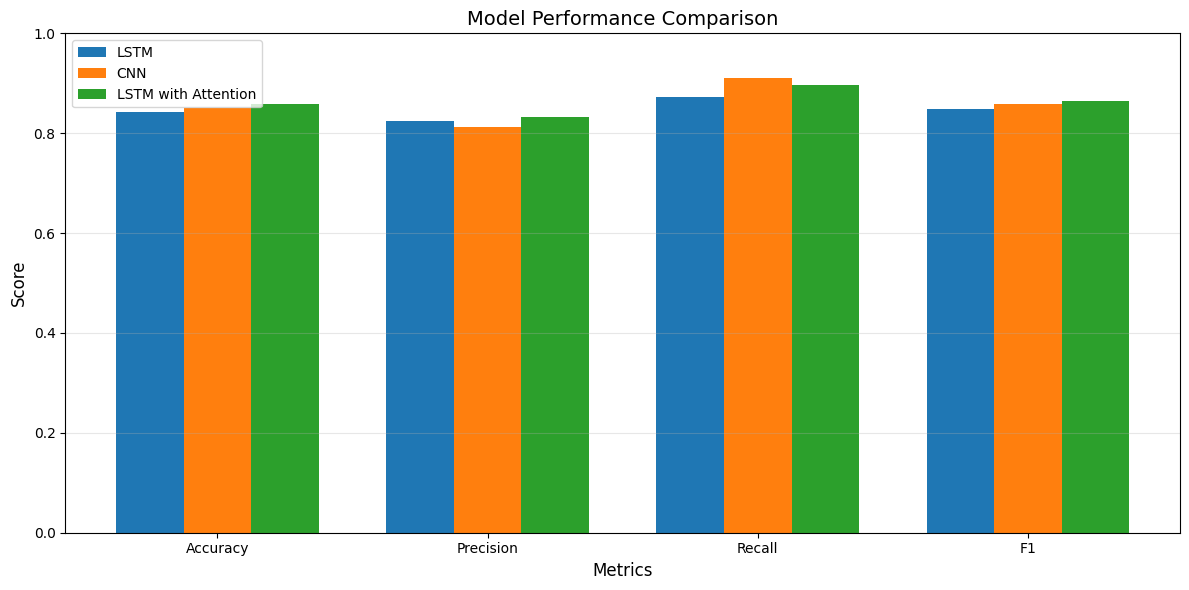

In [ ]:
# Step 7: Model Comparison Bar Chart
print("Visualizing Model Comparison...")

metrics = ['accuracy', 'precision', 'recall', 'f1']
model_names = list(all_results.keys())

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(metrics))
width = 0.25
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for idx, model_name in enumerate(model_names):
    values = [all_results[model_name][metric] for metric in metrics]
    ax.bar(x + idx * width, values, width, label=model_name, color=colors[idx])

ax.set_xlabel('Metrics', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14)
ax.set_xticks(x + width)
ax.set_xticklabels([m.capitalize() for m in metrics])
ax.legend()
ax.set_ylim([0, 1])
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()